In [49]:
%load_ext autoreload
%autoreload 2

from nntool.api import NNGraph
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
# import matplotlib.patches as patches
# %matplotlib widget
# import logging
# logging.basicConfig(level=logging.ERROR)
import pickle
import cv2
import torch
import os
import copy
import glob
import json
from tqdm import tqdm

import sys
sys.path.append("../../../yolox_people_detection/quantization")
from dataset_generators import CostomCOCODaset, get_annotations
sys.path.append("../../../yolox_people_detection")
from quantization.utils import hwc_slice
from decoding_layer.decoding import decode_C_style

sys.path.append("../../../yolox")
from yolox.data.data_augment import preproc as preprocess
from yolox.utils import multiclass_nms, demo_postprocess, vis

sys.path.append("../../../nn-shard-lite")
sys.path.append("../../../nn-shard-lite/src")
sys.path.append("../../../nn-shard-lite/src/utils")
from src.utils.metricsevaluator import MetricsEvaluator

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
G = NNGraph.load_graph("../../../yolox/weights/pg/best_ckpt.onnx", load_quantization=False)
max_activ_size, total_params = G.total_memory_usage
ops = G.total_ops

print(f"{G.name}:")
print(f"\tMax Active Size:\t{max_activ_size} elements")
print(f"\tTotal # Parameters:\t{total_params} elements")
print(f"\tTotal # Operations:\t{ops / 1e6:.2f} MOps")

## fix the order of the last layer to match that in pytorch 
G[-1].fixed_order = True

G.adjust_order()
G.add_dimensions()
G.fusions('scaled_match_group')
G.fusions('expression_matcher')

only align_corners is supported as coordinate_transformation_mode not asymmetric
_backbone_upsample_Resize - only round_prefer_ceil is supported for nearest mode not floor
only align_corners is supported as coordinate_transformation_mode not asymmetric
_backbone_upsample_1_Resize - only round_prefer_ceil is supported for nearest mode not floor


best_ckpt:
	Max Active Size:	614400 elements
	Total # Parameters:	889058 elements
	Total # Operations:	230.33 MOps


In [3]:
# calculate statistics
annotations = get_annotations("../../../YOLOX/datasets/pg_coco/annotations/instances_train2017.json")
# quant_dataset = CostomCOCODaset(
#     image_folder     = "../../../YOLOX/datasets/pg_coco/val2017",
#     annotations      = annotations,
#     max_size         = 1000,
#     input_size       = (192, 256),
#     transpose_to_chw = True,
#     input_channels   = 3,
#     img_type         = "rgb",
#     enable_slicing   = False
# )
quant_dataset = CostomCOCODaset(
    image_folder     = "../../../YOLOX/datasets/pg_coco/train2017",
    annotations      = annotations,
    max_size         = 250,
    input_size       = (240, 320),
    transpose_to_chw = True,
    input_channels   = 3,
    img_type         = "rgb",
    enable_slicing   = True
)

Loading annotations for class person...
loading annotations into memory...
Done (t=0.64s)
creating index...
index created!


In [4]:
sample = quant_dataset.__next__()

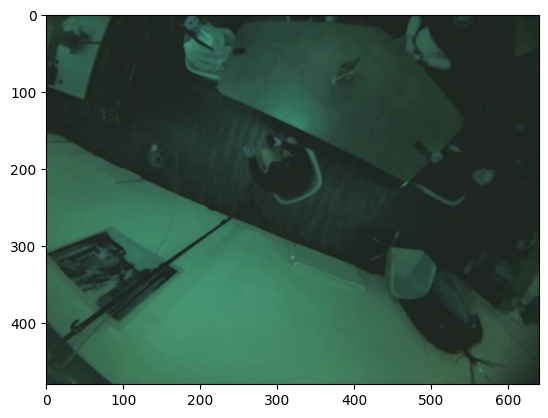

In [5]:
plt.imshow(quant_dataset.img)

In [6]:
float_execution = G.execute(sample, quantize=False)
float_out = [float_execution[out_node.step_idx][0] for out_node in G.outputs()]

In [7]:
float_boxes = float_out[0]

strides = [8, 16, 32]
feature_map_sizes = [(30, 40), (15, 20), (8, 10)]
decoded_float_boxes = decode_C_style(float_boxes.flatten(), feature_map_sizes, strides)

decoded_float_boxes = decoded_float_boxes.reshape(-1, 6)

decoded_float_boxes.shape

(1580, 6)

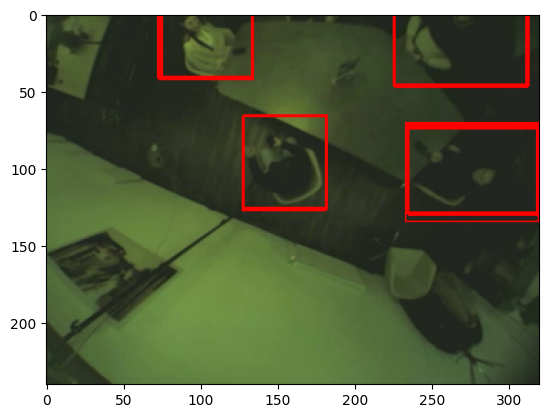

In [8]:
scores = decoded_float_boxes[:, -1] * decoded_float_boxes[:, -2]

boxes = decoded_float_boxes[scores > 0.5][:, :4].copy()
boxes_xyxy = np.ones_like(boxes)
boxes_xyxy[:, 0] = boxes[:, 0] - boxes[:, 2]/2.
boxes_xyxy[:, 1] = boxes[:, 1] - boxes[:, 3]/2.
boxes_xyxy[:, 2] = boxes[:, 0] + boxes[:, 2]/2.
boxes_xyxy[:, 3] = boxes[:, 1] + boxes[:, 3]/2.
boxes_xyxy = boxes_xyxy.astype(int)


tmp = quant_dataset.img.copy()
tmp = cv2.cvtColor(tmp, cv2.COLOR_BGR2RGB)
tmp = cv2.resize(tmp, (320, 240))
for box in boxes_xyxy:
    cv2.rectangle(tmp, box[:2], box[2:], (255, 0, 0), 1)

plt.imshow(tmp)

In [9]:
quant_dataset = CostomCOCODaset(
    image_folder     = "../../../YOLOX/datasets/pg_coco/train2017",
    annotations      = annotations,
    max_size         = 250,
    input_size       = (240, 320),
    transpose_to_chw = True,
    input_channels   = 3,
    img_type         = "rgb",
    enable_slicing   = True
)

In [10]:
stats = G.collect_statistics(quant_dataset)

with open("yolox_precalc.pickle", "wb") as f:
    pickle.dump(stats, f)

In [11]:
def clip_stats(stats, n_std):
    clipped_stats = copy.deepcopy(stats)
    if n_std:
        for layer, stat in stats.items():
            min_, max_ = stat['range_out'][0]['min'], stat['range_out'][0]['max']
            mean, std = stat['range_out'][0]['mean'], stat['range_out'][0]['std']
            clipped_stats[layer]['range_out'][0]['min'] = max(min_, mean - n_std * std)
            clipped_stats[layer]['range_out'][0]['max'] = min(max_, mean + n_std * std)
    return clipped_stats

In [12]:
stats = clip_stats(stats, n_std = 3)

print("Quantizing graph")
G.quantize(
    stats,
    graph_options={
        "bits": 8,
        "quantize_dimension": "channel",
        "use_ne16": True,
        "hwc": True
    },
    node_options= {
        'output_1' : 
            {
                'scheme' : 'float', 
                'float_type': 'float32'
            },
    },
)

Quantizing graph


In [13]:
quant_dataset = CostomCOCODaset(
    image_folder     = "../../../YOLOX/datasets/pg_coco/train2017",
    annotations      = annotations,
    max_size         = 100,
    input_size       = (240, 320),
    transpose_to_chw = False,
    input_channels   = 3,
    img_type         = "rgb",
    enable_slicing   = True
)

In [24]:
sample = quant_dataset.__next__()
sample.shape

(1, 120, 160, 12)

In [25]:
float_execution = G.execute(sample, quantize=False)
float_out = [float_execution[out_node.step_idx][0] for out_node in G.outputs()]

In [26]:
float_boxes = float_out[0]

strides = [8, 16, 32]
feature_map_sizes = [(30, 40), (15, 20), (8, 10)]
decoded_float_boxes = decode_C_style(float_boxes.flatten(), feature_map_sizes, strides)

decoded_float_boxes = decoded_float_boxes.reshape(-1, 6)

decoded_float_boxes.shape

(1580, 6)

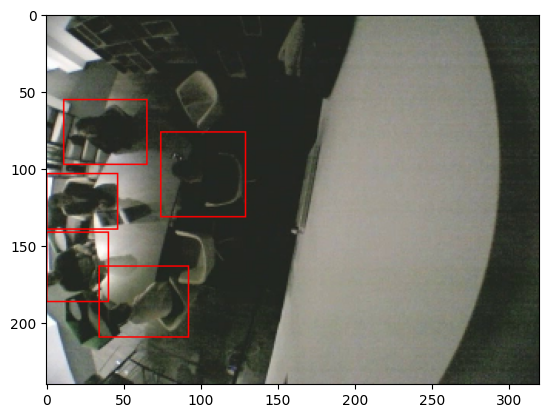

In [27]:
scores = decoded_float_boxes[:, -1] * decoded_float_boxes[:, -2]

boxes = decoded_float_boxes[scores > 0.5][:, :4].copy()
scores = scores[scores > 0.5]
boxes_xyxy = np.ones_like(boxes)
boxes_xyxy[:, 0] = boxes[:, 0] - boxes[:, 2]/2.
boxes_xyxy[:, 1] = boxes[:, 1] - boxes[:, 3]/2.
boxes_xyxy[:, 2] = boxes[:, 0] + boxes[:, 2]/2.
boxes_xyxy[:, 3] = boxes[:, 1] + boxes[:, 3]/2.
boxes_xyxy = boxes_xyxy.astype(int)

# Apply non-maximum suppression to filter out overlapping bounding boxes
indices = cv2.dnn.NMSBoxes(boxes_xyxy, scores, 0.5, 0.6)


tmp = quant_dataset.img.copy()
tmp = cv2.cvtColor(tmp, cv2.COLOR_BGR2RGB)
tmp = cv2.resize(tmp, (320, 240))
for box in boxes_xyxy[indices]:
    cv2.rectangle(tmp, box[:2], box[2:], (255, 0, 0), 1)

plt.imshow(tmp)

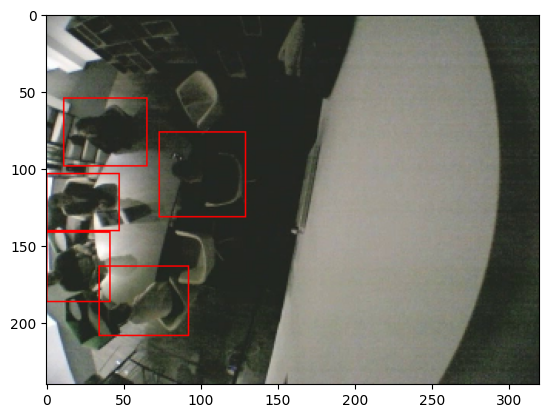

In [28]:
quant_execution = G.execute(sample, dequantize=True, quantize=True)
quant_out = [quant_execution[out_node.step_idx][0] for out_node in G.outputs()]

quant_boxes = quant_out[0]

strides = [8, 16, 32]
feature_map_sizes = [(30, 40), (15, 20), (8, 10)]
decoded_quant_boxes = decode_C_style(quant_boxes.flatten(), feature_map_sizes, strides)

decoded_quant_boxes = decoded_quant_boxes.reshape(-1, 6)

decoded_quant_boxes.shape

scores = decoded_quant_boxes[:, -1] * decoded_quant_boxes[:, -2]

boxes = decoded_quant_boxes[scores > 0.5][:, :4].copy()
scores = scores[scores > 0.5]
boxes_xyxy = np.ones_like(boxes)
boxes_xyxy[:, 0] = boxes[:, 0] - boxes[:, 2]/2.
boxes_xyxy[:, 1] = boxes[:, 1] - boxes[:, 3]/2.
boxes_xyxy[:, 2] = boxes[:, 0] + boxes[:, 2]/2.
boxes_xyxy[:, 3] = boxes[:, 1] + boxes[:, 3]/2.
boxes_xyxy = boxes_xyxy.astype(int)


# Apply non-maximum suppression to filter out overlapping bounding boxes
indices = cv2.dnn.NMSBoxes(boxes_xyxy, scores, 0.5, 0.6)


tmp = quant_dataset.img.copy()
tmp = cv2.cvtColor(tmp, cv2.COLOR_BGR2RGB)
tmp = cv2.resize(tmp, (320, 240))
for box in boxes_xyxy[indices]:
    cv2.rectangle(tmp, box[:2], box[2:], (255, 0, 0), 1)

plt.imshow(tmp)

In [45]:
annotation["category_id"]

0

In [58]:
def slicing(image):
    patch_top_left = image[..., ::2, ::2]
    patch_top_right = image[..., ::2, 1::2]
    patch_bot_left = image[..., 1::2, ::2]
    patch_bot_right = image[..., 1::2, 1::2]
    image = np.concatenate(
        (
            patch_top_left,
            patch_bot_left,
            patch_top_right,
            patch_bot_right,
        ),
        axis=0,
    )
    return image


def preproc(img, input_size, swap=(2, 0, 1), input_channels=3):
    if len(img.shape) == 3:
        padded_img = np.ones(
            (input_size[0], input_size[1], input_channels),
            dtype=np.uint8) * 114
    else:
        padded_img = np.ones(input_size, dtype=np.uint8) * 114

    r = min(input_size[0] / img.shape[0], input_size[1] / img.shape[1])
    resized_img = cv2.resize(
        img,
        (int(img.shape[1] * r), int(img.shape[0] * r)),
        interpolation=cv2.INTER_LINEAR,
    ).astype(np.uint8)

    if len(resized_img.shape) == 2:
        resized_img = resized_img[..., None]

    padded_img[: int(img.shape[0] * r), : int(img.shape[1] * r)] = resized_img
    padded_img = padded_img.transpose(swap)
    padded_img = np.ascontiguousarray(padded_img, dtype=np.float32)
    return padded_img


def preprocessing(img_file, input_size, enable_slicing=True, transpose_to_chw=False, input_channels=3):
    # read image as BGR
    image = cv2.imread(
        img_file,
        cv2.IMREAD_UNCHANGED
    )
    if image is None:
        img_file = img_file.replace(".jpg", ".ppm").replace(".jpeg", ".ppm")
        image = cv2.imread(
            img_file,
            cv2.IMREAD_UNCHANGED
        )

    if len(image.shape) == 2:
        image = np.expand_dims(image, axis=2)

    image = preproc(
        image, 
        input_size, 
        input_channels = input_channels
    )

    if enable_slicing:
        image = slicing(image)

    if not transpose_to_chw:
        image = image.transpose(1, 2, 0)

    return image[None]


def postprocess(output, conf_th):
    strides = [8, 16, 32]
    feature_map_sizes = [(30, 40), (15, 20), (8, 10)]
    decoded_boxes = decode_C_style(output.flatten(), feature_map_sizes, strides)

    decoded_boxes = decoded_boxes.reshape(-1, 6)

    decoded_boxes.shape

    scores = decoded_boxes[:, -1] * decoded_boxes[:, -2]

    boxes = decoded_boxes[scores > conf_th][:, :4].copy()
    scores = scores[scores > conf_th]
    boxes_xyxy = np.ones_like(boxes)
    boxes_xyxy[:, 0] = boxes[:, 0] - boxes[:, 2]/2.
    boxes_xyxy[:, 1] = boxes[:, 1] - boxes[:, 3]/2.
    boxes_xyxy[:, 2] = boxes[:, 0] + boxes[:, 2]/2.
    boxes_xyxy[:, 3] = boxes[:, 1] + boxes[:, 3]/2.
    boxes_xyxy = boxes_xyxy.astype(int)

    # Apply non-maximum suppression to filter out overlapping bounding boxes
    indices = cv2.dnn.NMSBoxes(boxes_xyxy, scores, conf_th, 0.65)

    return boxes_xyxy[indices], scores[indices]

In [139]:
evaluator = MetricsEvaluator(
    is_relative_coordinates=False,
    is_xywh_coordinates=True,
)

with open("../../../YOLOX/datasets/pg_coco/annotations/instances_test.json", "rt") as f:
    test_data = json.load(f)

name_mapper = {}
id_mapper = {}
for i in test_data["images"]:
    name_mapper[i["file_name"]] = i["id"]
    id_mapper[i["id"]] = i["file_name"]

for annotation in test_data["annotations"]:
    
    img_data = [i for i in test_data["images"] if i["id"] == annotation["image_id"]][0]
    w = img_data["width"]
    h = img_data["height"]
    evaluator.add_gt_box(
        img_path=annotation["image_id"],
        class_name=annotation["category_id"],
        bbox=np.array(annotation["bbox"]) / [w, h, w, h] * [320, 240, 320, 240]
    )
    # break

img_pths = sorted(glob.glob("../../../YOLOX/datasets/pg_coco/test2017/*.jpg"))

In [140]:
score_thr = 0.3

for img_pth in tqdm(img_pths):
    img_name = os.path.basename(img_pth)
    image_data = preprocessing(img_pth, (240, 320))
    
    # execution = G.execute(image_data, quantize=False) #, dequantize=True)
    execution = G.execute(image_data, quantize=True, dequantize=True)
    # output = [execution[out_node.step_idx][0] for out_node in G.outputs()[:1]]

    output = [execution[out_node.step_idx][0] for out_node in G.outputs()][0]

    boxes, scores = postprocess(output, score_thr)
    
    # tmp = cv2.imread(img_pth)
    # tmp = cv2.resize(tmp, (320, 240))
    # for box in boxes:
    #     cv2.rectangle(tmp, box[:2], box[2:], (255, 0, 0), 1)

    # plt.imshow(tmp)
    
    for b, s in zip(boxes, scores):
        evaluator.add_det_box(
            img_path=name_mapper[os.path.basename(img_pth)],
            class_name=0,
            bbox=np.concatenate([b[:2], b[2:] - b[:2]]),
            confidence=s
        )
    # break

100%|██████████| 4558/4558 [52:40<00:00,  1.44it/s]


In [141]:
res = evaluator.eval_conf_vals(0.5, 1)[0]

In [142]:
precision = res["total TP"] / (res["total TP"] + res["total FP"])
recall = res["total TP"] / (res["total positives"])

f_score = 2 * precision * recall / (precision + recall)

precision, recall, f_score, res['AP']

(0.94933197050449, 0.9399985541820285, 0.9446422084998185, 0.9336530856410452)

Text(0, 0.5, 'precision')

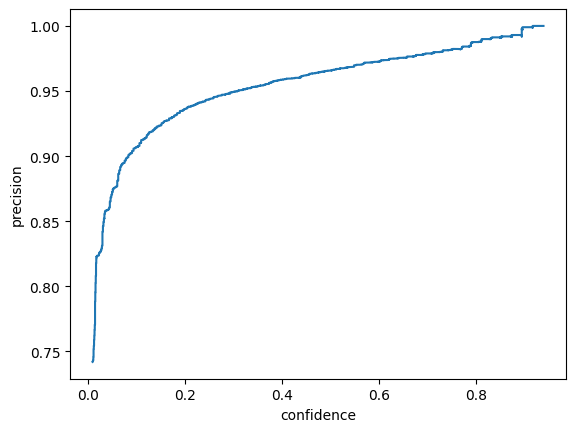

In [131]:
plt.plot(res["confidence"], res["precision"])
plt.xlabel("confidence")
plt.ylabel("precision")

Text(0, 0.5, 'recall')

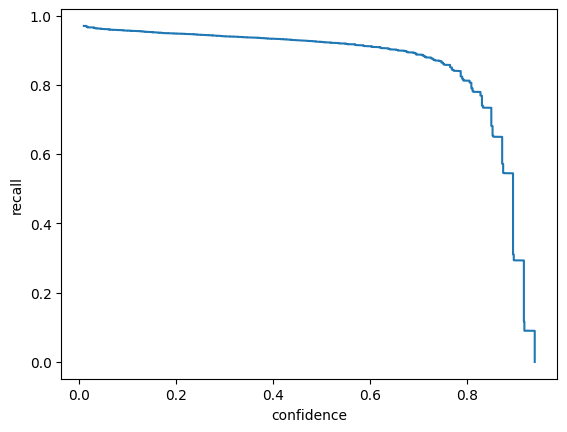

In [132]:
plt.plot(res["confidence"], res["recall"], label="exp5")
plt.xlabel("confidence")
plt.ylabel("recall")

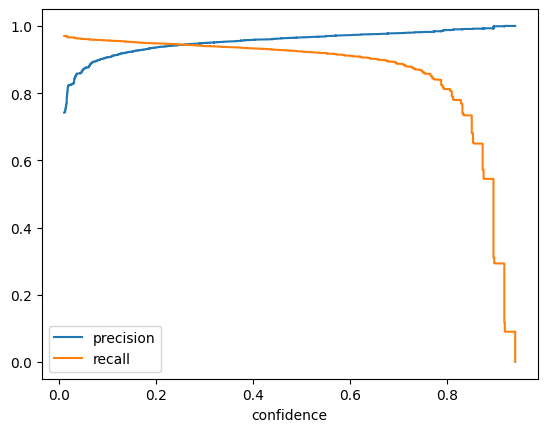

In [133]:
plt.plot(res["confidence"], res["precision"], label="precision")
plt.plot(res["confidence"], res["recall"], label="recall")

plt.xlabel("confidence")
plt.legend()

Text(0, 0.5, 'precision')

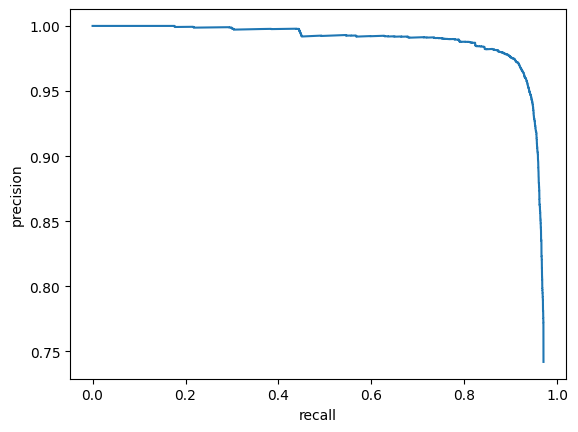

In [134]:
plt.plot(res["recall"], res["precision"])
plt.xlabel("recall")
plt.ylabel("precision")